# We load data from the Eurocrops dataset. First, I will chooose one region and year. 

In [2]:
#set working directory to project root
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)

/Users/henristaehelin/Desktop/UZH/SDS320/project


### 1. Data load. I chose to load data from germany in 2023. 

In [4]:
import geopandas as gpd
germany_2023 = gpd.read_parquet("../data/raw/vectors/dea_2023.parquet")
germany_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491..."
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615..."
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426..."
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293..."
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427..."


We have the cropfield number, the geometry, but what about the crop type label?

Could that be original_code?

In [5]:
import pandas as pd
crop_names = pd.read_csv("../data/raw/Eurocrops.csv")
crop_names.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,at,10001,NICHT DEFINIERT,not defined,3390000000,not_known_and_other,0,No specified use
1,at,105,KÖRNERMAIS,GRAIN CORN,3310106000,maize_corn_popcorn,6,Harvested as Grains
2,at,106,MAIS CORN-COB-MIX (CCM),CORN CORN-COB-MIX (CCM),3310106000,maize_corn_popcorn,0,No specified use
3,at,107,ZUCKERMAIS,SUGAR CORN,3310106000,maize_corn_popcorn,0,No specified use
4,at,109,SILOMAIS,SILO CORN,3310106000,maize_corn_popcorn,3,Fodder/Forage


This file has all the codes for each country. "nuts" is the country tag. So for italy it would be iti1. We want the table of country specific crop codes of only italy. 

In [ ]:
germany_cropnames = crop_names[crop_names["nuts"] == "dea"] #select only rows with german codes
germany_cropnames.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
1809,dea,10222,Dicke Bohne,Broad bean,3310201010,beans,0,No specified use
1810,dea,112,Winterdurum (Hartweizen),Winter hard wheat / durum,3310102001,winter_durum_hard_wheat,0,No specified use
1811,dea,113,Sommerdurum (Hartweizen),Summer durum wheat / durum,3310102002,spring_durum_hard_wheat,0,No specified use
1812,dea,114,Winter-Dinkel,Winter spelt,3310110001,winter_spelt,0,No specified use
1813,dea,115,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use


Merge them with the german crop dataset, now we will have the polygons with the labels. 
#### **Consider generalizing this process into a python script that we can call upon, this would allow us to efficiently combine multiple vector datasets from different countries into one.**

In [7]:
germany_2023 = germany_2023.merge(
    germany_cropnames,
    on=["original_code"],
    how="left")
germany_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491...",dea,Blühfläche (AUM-Altmaßnahme,Flowering area (AUM-old measure),3310800000,flowers_ornamental_plants,0,No specified use
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615...",dea,Kond.-Brache (aktive Begrünun,Fallow land (active greening),3311100000,fallow_land_not_crop,0,No specified use
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293...",dea,Unbefestigte Mieten AL,unfixed rents AL,3390000000,not_known_and_other,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use


We now have polygons and labels. We will use hcat4_name as this is the harmonized label across multiple countries.

Lets also see how many unique crops there are. 

In [13]:
#see number of unique crops
print(germany_2023["hcat4_name"].nunique())
print(germany_2023["hcat4_code"].nunique()) #making sure number of unique names and codes line up

173
173


#### Thats a lot of crop types, I think its easier to learn less first. Lets see what types of crops there are.

In [16]:
print(germany_2023["hcat4_name"].unique())

['flowers_ornamental_plants' 'fallow_land_not_crop' 'permanent_grassland'
 'not_known_and_other' 'asparagus' 'potatoes' 'ericaceae_heather'
 'winter_common_soft_wheat' 'onions' 'winter_barley' 'spring_barley'
 'spring_oats' 'temporary_grassland' 'rhubarb' 'berries_berry_species'
 'clover' 'unmaintained' 'orchards_fruits' 'winter_durum_hard_wheat'
 'cereal' 'beans' 'winter_rapeseed_rape' 'conifers' 'winter_rye'
 'winter_triticale' 'miscanthus_silvergrass' 'sugar_beet'
 'alfalfa_lucerne' 'maize_corn_popcorn' 'fresh_vegetables' 'arable_crops'
 'brassicaceae_cruciferae' 'strawberries' 'sunflower'
 'winter_mixed_grains' 'winter_spelt'
 'aromatic_medicinal_culinary_plants_spices_herbs'
 'spring_common_soft_wheat' 'spring_triticale' 'peas' 'celery' 'spinach'
 'cucumber_pickle' 'winter_oats' 'lupins' 'pumpkin_squash_gourd'
 'carrots_daucus' 'seed_seedlings' 'nurseries_nursery'
 'permanent_crops_perennial' 'poaceae_grasses' 'radish' 'peony_peonies'
 'hazelnuts_hazel' 'elymus' 'edelweiss' 'other

#### There are a lot of crops that are not relevant or may be to difficult to identify. I made a list. 
fallow_land_not_crop, not_known_and_other, unmaintained, seed_seedlings, nurseries_nursery, poaceae_grasses, other_flowers_ornamental_plants, flowers_ornamental_plants, other_aromatic_medicinal_culinary_plants_spices_herbs, afforestation_reforestation, spring_mixed_grains, other_industrial_crops, other_poaceae_grasses, other_arable_land_crops

This is 14 types that don't work, this still leaves me with 159 crop types. I think it might make most sense to pick 30 and then see from there. 

#### Instead lets choose 30 different crop types. 

In [25]:
# Check the number of polygons per crop type
crop_counts = germany_2023["hcat4_name"].value_counts()

subset = [
    "winter_common_soft_wheat", "winter_barley", "spring_barley", "winter_rapeseed_rape",
    "maize_corn_popcorn", "sugar_beet", "potatoes", "winter_rye", "winter_triticale",
    "winter_oats", "spring_oats", "winter_spelt", "winter_durum_hard_wheat", "spring_common_soft_wheat",
    "winter_mixed_grains", "sunflower", "soy_soybeans", "peas", "beans", "lupins",
    "temporary_grassland", "permanent_grassland", "alfalfa_lucerne", "clover",
    "winter_emmer", "buckwheat", "miscanthus_silvergrass", "asparagus", "strawberries", "carrots_daucus",
]

print(crop_counts.reindex(subset, fill_value=0))

hcat4_name
winter_common_soft_wheat     69959
winter_barley                43410
spring_barley                 3529
winter_rapeseed_rape         16689
maize_corn_popcorn           91195
sugar_beet                   13079
potatoes                     11308
winter_rye                   15277
winter_triticale             17376
winter_oats                    536
spring_oats                   3289
winter_spelt                   808
winter_durum_hard_wheat        685
spring_common_soft_wheat      1320
winter_mixed_grains             85
sunflower                      409
soy_soybeans                   220
peas                          2117
beans                         3072
lupins                         250
temporary_grassland          28327
permanent_grassland         294894
alfalfa_lucerne               1506
clover                        5298
winter_emmer                    28
buckwheat                       34
miscanthus_silvergrass         790
asparagus                     1672
strawberr

#### Lets create a subset from these crop types, from this we will choose scenes that have at least 10 different crop types.

In [33]:
# Keep only the 30 selected crop types
reduced_crops = germany_2023[
    germany_2023["hcat4_name"].isin(subset)
].copy()

print("Original polygons:", len(germany_2023))
print("Subset polygons:", len(reduced_crops))
print("Crop types present:", reduced_crops["hcat4_name"].nunique())

reduced_crops.head(5)

Original polygons: 748208
Subset polygons: 629482
Crop types present: 30


,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use
6,714367,602,7209215,0.6296,0.629910,"MULTIPOLYGON (((4115046.183 3117774.226, 41151...",dea,Kartoffeln,potatoes,3310300000,potatoes,0,No specified use
9,716260,115,7061460,2.4301,2.432082,"MULTIPOLYGON (((4243063.131 3249725.238, 42432...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use
11,716867,115,7132898,2.0211,2.022715,"MULTIPOLYGON (((4242002.866 3240369.434, 42420...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use


#### Now we want to select areas that have at least 10 different crop types. 

In [38]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box

# Use your filtered crop dataset
germany_utm = reduced_crops.to_crs("EPSG:32632")

minx, miny, maxx, maxy = germany_utm.total_bounds #sets the bounds the polygons based on germany
cell_size = 2000  # 2 km

x_coords = np.arange(
    np.floor(minx / cell_size) * cell_size,
    maxx,
    cell_size
)
y_coords = np.arange(
    np.floor(miny / cell_size) * cell_size,
    maxy,
    cell_size
)

grid = gpd.GeoDataFrame(
    {"area_id": range(len(x_coords) * len(y_coords))},
    geometry=[
        box(x, y, x + cell_size, y + cell_size)
        for x in x_coords
        for y in y_coords
    ],
    crs=germany_utm.crs
)

# Count crop types intersecting each grid cell
joined = gpd.sjoin(
    germany_utm[["hcat4_name", "geometry"]],
    grid[["area_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

crop_counts = (
    joined.groupby("area_id")["hcat4_name"]
    .nunique()
    .rename("n_crop_types")
)

grid = grid.join(crop_counts, on="area_id")
grid["n_crop_types"] = grid["n_crop_types"].fillna(0).astype(int)

# Find areas with at least 10 different crop types
candidates = (
    grid[grid["n_crop_types"] >= 10]
    .sort_values("n_crop_types", ascending=False)
    .copy()
)

print("Suitable areas found:", len(candidates))
display(candidates[["area_id", "n_crop_types"]].head(20))

Suitable areas found: 3327


,area_id,n_crop_types
4699,4699,19
5192,5192,19
3712,3712,19
10643,10643,19
3730,3730,18
12763,12763,18
14336,14336,18
2848,2848,18
3369,3369,18
2366,2366,18


We have lots of suitable areas, lets select the 5 with the most crop types. 

In [39]:
selected = []

for _, candidate in candidates.iterrows():
    if all(
        not candidate.geometry.intersects(existing.geometry)
        for existing in selected
    ):
        selected.append(candidate)

    if len(selected) == 5:
        break

selected_areas = gpd.GeoDataFrame(
    selected,
    crs=grid.crs
)

print(f"Selected {len(selected_areas)} areas")
display(selected_areas[["area_id", "n_crop_types"]])

Selected 5 areas


,area_id,n_crop_types
4699,4699,19
5192,5192,19
3712,3712,19
10643,10643,19
3730,3730,18


#### We now have 5 suitable 2 by 2 km areas that we can use. Lets take one and combine it with Sentinel 2 data. 

### 2. We want to combine it now with the Sentinel-2 raster data and load them together. 

In [34]:
reduced_crops.crs
#first check CRS

<Projected CRS: EPSG:3035>
Name: ETRS89-extended / LAEA Europe
Axis Info [cartesian]:
- Y[north]: Northing (metre)
- X[east]: Easting (metre)
Area of Use:
- name: Europe - European Union (EU) countries and candidates. Europe - onshore and offshore: Albania; Andorra; Austria; Belgium; Bosnia and Herzegovina; Bulgaria; Croatia; Cyprus; Czechia; Denmark; Estonia; Faroe Islands; Finland; France; Germany; Gibraltar; Greece; Hungary; Iceland; Ireland; Italy; Kosovo; Latvia; Liechtenstein; Lithuania; Luxembourg; Malta; Monaco; Montenegro; Netherlands; North Macedonia; Norway including Svalbard and Jan Mayen; Poland; Portugal including Madeira and Azores; Romania; San Marino; Serbia; Slovakia; Slovenia; Spain including Canary Islands; Sweden; Switzerland; Türkiye (Turkey); United Kingdom (UK) including Channel Islands and Isle of Man; Vatican City State.
- bounds: (-35.58, 24.6, 44.83, 84.73)
Coordinate Operation:
- name: Europe Equal Area 2001
- method: Lambert Azimuthal Equal Area
Datum: Eur

In [46]:
selected_wgs84 = selected_areas.to_crs("EPSG:4326")

print(selected_wgs84.crs)

EPSG:4326


In [47]:
from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

items_by_area = {}

for _, area in selected_wgs84.iterrows():
    area_id = area["area_id"]
    geometry = area.geometry.__geo_interface__

    search = pc_catalog.search(
        collections=["sentinel-2-l2a"],
        intersects=geometry,
        datetime="2023-01-01/2023-12-31",
        query={"eo:cloud_cover": {"lt": 20}},
        max_items=10,
    )

    items = list(search.items())
    items_by_area[area_id] = items

    print(f"Area {area_id}: found {len(items)} scenes")

Area 4699: found 10 scenes
Area 5192: found 10 scenes
Area 3712: found 10 scenes
Area 10643: found 10 scenes
Area 3730: found 10 scenes


##### Select the best scenes (least cloud cover) for each area. 

In [49]:
import planetary_computer as pc

best_items = {}

for area_id, items in items_by_area.items():

    if not items:
        print(f"No Sentinel-2 scenes found for area {area_id}")
        continue

    items_sorted = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 999),
    )

    s2_item = pc.sign(items_sorted[0])
    best_items[area_id] = s2_item

    print(f"\nArea: {area_id}")
    print("Selected item:", s2_item.id)
    print("Date:", s2_item.datetime)
    print(
        "Cloud cover:",
        round(s2_item.properties.get("eo:cloud_cover", 999), 2),
    )

    print("Useful assets:")
    for key in ["B02", "B03", "B04", "B08", "SCL", "visual"]:
        if key in s2_item.assets:
            print(key, "-", s2_item.assets[key].title)


Area: 4699
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image

Area: 5192
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image

Area: 3712
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image

Area: 10643
Selected item: S2A_MSIL2A_2023090

##### Save the bands for each scene in each area.

In [50]:
from pathlib import Path
from scripts.Raster_helper_functions import save_multiband_subset

output_dir = Path("../data/raw/imagery/sentinel2")
output_dir.mkdir(parents=True, exist_ok=True)

s2_paths = {}

for _, area in selected_wgs84.iterrows():

    area_id = area["area_id"]

    if area_id not in best_items:
        continue

    s2_item = best_items[area_id]

    # Bounding box in WGS84: [min_lon, min_lat, max_lon, max_lat]
    bbox_wgs84 = list(area.geometry.bounds)

    output_path = output_dir / f"germany_2023_area_{area_id}.tif"

    s2_path = save_multiband_subset(
        item=s2_item,
        asset_keys=[
            "B02",  # Blue
            "B03",  # Green
            "B04",  # Red
            "B08",  # Near-infrared
        ],
        bbox_wgs84=bbox_wgs84,
        output_path=output_path,
    )

    s2_paths[area_id] = s2_path

print("\nDownloaded areas:", len(s2_paths))

Saved: ../data/raw/imagery/sentinel2/germany_2023_area_4699.tif (0.26 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_5192.tif (0.26 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_3712.tif (0.26 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_10643.tif (0.25 MB)
Saved: ../data/raw/imagery/sentinel2/germany_2023_area_3730.tif (0.26 MB)

Downloaded areas: 5


In [51]:
import leafmap
import rasterio

maps = {}

for area_id, raster_path in s2_paths.items():

    # Get the crop fields for this selected area
    area = selected_areas.loc[
        selected_areas["area_id"] == area_id
    ].to_crs(reduced_crops.crs)

    crop_fields = gpd.clip(
        reduced_crops,
        area
    )

    m = leafmap.Map(height="500px")
    m.add_basemap("Esri.WorldImagery")

    # True-colour RGB (B04, B03, B02)
    m.add_raster(
        str(raster_path),
        indexes=[3, 2, 1],
        layer_name="Sentinel-2 True Color",
    )

    # False-colour composite (B08, B04, B03)
    m.add_raster(
        str(raster_path),
        indexes=[4, 3, 2],
        layer_name="Sentinel-2 False Color",
    )

    m.add_gdf(
        crop_fields,
        layer_name="German Crop Fields",
    )

    m.add_layer_control()
    maps[area_id] = m

    print(f"Map for area {area_id}")
    display(m)

Map for area 4699


Map(center=[50.7770925, 6.971693], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

Map for area 5192


Map(center=[50.7969865, 7.084332], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

Map for area 3712


Map(center=[50.719008, 6.747504], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', …

Map for area 10643


Map(center=[51.512167, 8.32272], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', '…

Map for area 3730


Map(center=[51.042525999999995, 6.7318305], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_i…

## 3. Data Preprocessing

While we can visually confirm that the polygons match up onto the satellite data. We want to check crs of both vector and raster data to make sure they are the same. Also we can check the bounds while we are at it.

In [14]:
import rasterio

with rasterio.open(s2_item.assets["B04"].href) as src:
    raster_crs = src.crs
    raster_bounds = src.bounds
    raster_extent = box(*raster_bounds)

print("Raster CRS:", raster_crs)
print("Vector CRS:", italy_subset.crs)
print("Raster bounds:", raster_bounds)
print("Vector bounds:", italy_subset.total_bounds)
print("Raster Extent:", raster_extent)


NameError: name 'box' is not defined

#### See! They weren't actually the same CRS, we need to correct. Also the bounds are not the same. 

In [15]:
italy_subset = italy_subset.to_crs("EPSG:32632")
print("Vector CRS:", italy_subset.crs)

Vector CRS: EPSG:32632


Now lets map again real quick for another check.

In [17]:
#We filter to keep only the polygons ones within the raster extent
inside = italy_subset.geometry.within(raster_extent)
italy_inside = italy_subset.loc[inside].copy()

print("Features fully inside image:", len(italy_inside))
print("Features touching or crossing image boundary:", len(italy_subset) - len(italy_inside))

NameError: name 'raster_extent' is not defined

This is odd, i can clearly see that there are polygons covering the image boundary, but the code can't identify them. The crs is the same, perhaps its the fact that the bounds are different? I thought that was what I was correcting for though. 

## 4. Converting vector data in a raster mask. 

First we need to define an output path so that our rasterised vector data is a clear place. 

In [52]:
from pathlib import Path

import geoai

output_path = Path("../data/raw/raster/germany_mask.tif")
output_path

PosixPath('../data/raw/raster/germany_mask.tif')

##### create a numeric ID for the crops

In [54]:
# Create a numeric class ID for each crop type
crop_names = sorted(reduced_crops["hcat4_name"].dropna().unique())

crop_mapping = {
    name: i + 1
    for i, name in enumerate(crop_names)
}

reduced_crops = reduced_crops.copy()
reduced_crops["crop_id"] = (
    reduced_crops["hcat4_name"].map(crop_mapping)
)

print("Number of crop classes:", len(crop_mapping))
print(crop_mapping)

Number of crop classes: 30
{'alfalfa_lucerne': 1, 'asparagus': 2, 'beans': 3, 'buckwheat': 4, 'carrots_daucus': 5, 'clover': 6, 'lupins': 7, 'maize_corn_popcorn': 8, 'miscanthus_silvergrass': 9, 'peas': 10, 'permanent_grassland': 11, 'potatoes': 12, 'soy_soybeans': 13, 'spring_barley': 14, 'spring_common_soft_wheat': 15, 'spring_oats': 16, 'strawberries': 17, 'sugar_beet': 18, 'sunflower': 19, 'temporary_grassland': 20, 'winter_barley': 21, 'winter_common_soft_wheat': 22, 'winter_durum_hard_wheat': 23, 'winter_emmer': 24, 'winter_mixed_grains': 25, 'winter_oats': 26, 'winter_rapeseed_rape': 27, 'winter_rye': 28, 'winter_spelt': 29, 'winter_triticale': 30}


##### Rasterize the polygons for each crop area

In [55]:
from pathlib import Path
import geopandas as gpd
import geoai

output_dir = Path("../data/raw/raster")
output_dir.mkdir(parents=True, exist_ok=True)

mask_paths = {}

for area_id, s2_path in s2_paths.items():

    # Get the selected 2 km × 2 km area
    area = selected_areas.loc[
        selected_areas["area_id"] == area_id
    ]

    # Reproject the area to match the vector data CRS
    area = area.to_crs(reduced_crops.crs)

    # Keep crop polygons intersecting this area
    crop_fields = gpd.clip(reduced_crops, area)

    # Output file for this area's crop labels
    mask_path = output_dir / f"germany_mask_{area_id}.tif"

    geoai.vector_to_raster(
        crop_fields,
        str(mask_path),
        reference_raster=str(s2_path),
        attribute_field="crop_id",
        dtype="int16",
    )

    mask_paths[area_id] = mask_path

    print(f"Saved mask for area {area_id}: {mask_path}")

Saved mask for area 4699: ../data/raw/raster/germany_mask_4699.tif
Saved mask for area 5192: ../data/raw/raster/germany_mask_5192.tif
Saved mask for area 3712: ../data/raw/raster/germany_mask_3712.tif
Saved mask for area 10643: ../data/raw/raster/germany_mask_10643.tif
Saved mask for area 3730: ../data/raw/raster/germany_mask_3730.tif


In [56]:
import numpy as np
import rasterio

for area_id, mask_path in mask_paths.items():
    with rasterio.open(mask_path) as src:
        mask = src.read(1)

        print(
            f"Area {area_id}:",
            "shape =", mask.shape,
            "| CRS =", src.crs,
            "| classes =", np.unique(mask),
        )

Area 4699: shape = (200, 211) | CRS = EPSG:32632 | classes = [ 0  2  3  7  8 11 12 13 14 15 16 17 18 19 20 21 22 27 28 30]
Area 5192: shape = (200, 210) | CRS = EPSG:32632 | classes = [ 0  1  2  3  6  7  8  9 10 11 12 13 17 18 19 20 21 22 27 28]
Area 3712: shape = (200, 212) | CRS = EPSG:32632 | classes = [ 0  1  2  3  8 10 11 12 14 15 16 17 18 20 21 22 27 28 29 30]
Area 10643: shape = (200, 204) | CRS = EPSG:32632 | classes = [ 0  1  3  6  8 10 11 12 13 14 16 17 18 20 21 22 27 28 29 30]
Area 3730: shape = (216, 195) | CRS = EPSG:32631 | classes = [ 0  1  3  6  7  8 10 11 12 15 18 20 21 22 25 26 27 28 30]


#### This check shows us that the mask is made up of each different crop type, not just a binary 0, 255 mask of crop vs non crops

##### Here we also plot one area and its agricultural mask to show the rasterization.
The areas in dark blue are 0 or no crops. 

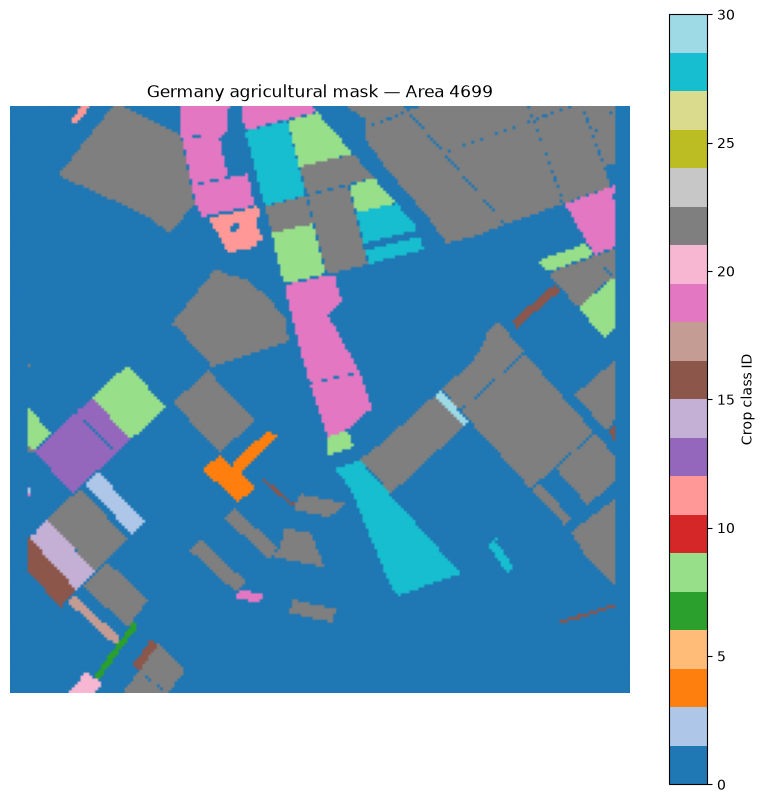

In [58]:
import matplotlib.pyplot as plt
import rasterio
import numpy as np

# Select one area
area_id = next(iter(mask_paths))
mask_path = mask_paths[area_id]

with rasterio.open(mask_path) as src:
    mask = src.read(1)

plt.figure(figsize=(10, 10))
plt.imshow(mask, cmap="tab20")
plt.colorbar(label="Crop class ID")
plt.title(f"Germany agricultural mask — Area {area_id}")
plt.axis("off")
plt.show()